# House Price Prediction: From Raw Listings to a Reliable Model

A complete, end-to-end machine learning project that estimates the selling price of a house from its features, and checks every step with proper statistics.

**What you will find in this notebook**

| Part | What happens |
|---|---|
| 1 | The problem and the plan |
| 2 | Setting up the tools |
| 3 | Where the data comes from |
| 4 | A first look at the data |
| 5 | Cleaning the data |
| 6 | Exploring the data visually |
| 7 | Testing our hunches statistically |
| 8 | Preparing features for modelling |
| 9 | Splitting the data and building the pipeline |
| 10 | Comparing candidate models |
| 11 | Tuning the best contender |
| 12 | The final exam on unseen houses |
| 13 | Checking the model's assumptions |
| 14 | What actually drives house prices |
| 15 | Trying the model on a brand-new house |
| 16 | Saving our work |
| 17 | Conclusions, limitations and next steps |

## 1. What Problem Are We Solving?

Imagine you are helping a buyer, a seller or a bank decide what a house is worth. A fair price depends on many things at once: how big the house is, where it sits, how old it is, what condition it is in, and more.

**Goal:** build a regression model that predicts the sale price of a house from its features, and understand *why* it predicts what it does.

**How we will judge success**

- **MAE** (Mean Absolute Error): on average, how many dollars are we off?
- **RMSE** (Root Mean Squared Error): like MAE, but punishes big misses harder.
- **R²**: the share of price variation the model explains.
- **Statistical checks**: do the relationships we rely on hold up under proper hypothesis tests, and do the model's errors behave sensibly?

## 2. Getting Set Up

First we import the libraries we need and fix a random seed, so that anyone who runs this notebook gets exactly the same numbers and charts.

In [ ]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy import stats

from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.titleweight"] = "bold"
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = 30

RANDOM_STATE = 42
CURRENT_YEAR = 2026

## 3. Where the Data Comes From

Public housing datasets are great, but they often need a download, a licence check, or a login. To keep this notebook **fully self-contained and reproducible**, we generate a realistic housing market of 2,000 listings ourselves.

The data is simulated, but it is built to behave like the real thing:

- Four neighbourhood types (Downtown, Suburban, Lakeside, Rural) with different typical house sizes, plot sizes and distances from the city centre.
- Price grows with size, but with diminishing returns, and carries a location premium or discount.
- Older houses and houses far from the centre sell for less; better condition and a garage add value.
- Prices have natural random noise, because no two buyers are alike.

To make the cleaning step meaningful, we also add the kinds of mess real data always has: **missing values, duplicate rows and a few data-entry typos**.

> Because the data is simulated, the conclusions describe this simulated market, not a real city. The workflow, however, is exactly what you would apply to a real dataset such as Ames Housing or California Housing.

In [ ]:
rng = np.random.default_rng(RANDOM_STATE)
n = 2000

# --- Location --------------------------------------------------------------
neighborhoods = ["Downtown", "Suburban", "Lakeside", "Rural"]
neighborhood = rng.choice(neighborhoods, size=n, p=[0.20, 0.45, 0.15, 0.20])

typical_sqft  = pd.Series({"Downtown": 1300, "Suburban": 2000, "Lakeside": 2300, "Rural": 2100})
typical_lot   = pd.Series({"Downtown": 2500, "Suburban": 7000, "Lakeside": 9000, "Rural": 30000})
garage_chance = pd.Series({"Downtown": 0.35, "Suburban": 0.85, "Lakeside": 0.80, "Rural": 0.90})
dist_low      = pd.Series({"Downtown": 0.5, "Suburban": 5, "Lakeside": 8,  "Rural": 20})
dist_high     = pd.Series({"Downtown": 4.0, "Suburban": 20, "Lakeside": 25, "Rural": 60})
location_effect = pd.Series({"Downtown": 0.15, "Suburban": 0.00, "Lakeside": 0.25, "Rural": -0.20})

# --- Physical features -----------------------------------------------------
size_mean = typical_sqft[neighborhood].to_numpy()
sqft = np.clip(rng.normal(size_mean, 0.25 * size_mean), 550, 6000).round(-1)

bedrooms  = np.clip(np.round(sqft / 700 + rng.normal(0, 0.7, n)), 1, 6).astype(int)
bathrooms = np.clip(np.round(0.6 * bedrooms + rng.normal(0, 0.5, n)), 1, 5).astype(int)
year_built = rng.integers(1950, 2025, n)
lot_size = (typical_lot[neighborhood].to_numpy() * rng.lognormal(0, 0.35, n)).round(-1)
has_garage = (rng.random(n) < garage_chance[neighborhood].to_numpy()).astype(int)
condition = rng.choice([1, 2, 3, 4, 5], size=n, p=[0.05, 0.15, 0.40, 0.30, 0.10])
distance_km = rng.uniform(dist_low[neighborhood].to_numpy(), dist_high[neighborhood].to_numpy())

# --- The "true" price recipe (hidden from the model) ----------------------
age = CURRENT_YEAR - year_built
log_price = (
    6.7
    + 0.75 * np.log(sqft)
    + 0.05 * np.log(lot_size)
    + location_effect[neighborhood].to_numpy()
    + 0.06 * (condition - 3)
    + 0.05 * has_garage
    + 0.04 * bathrooms
    - 0.004 * age
    - 0.006 * distance_km
    + rng.normal(0, 0.12, n)
)
price = np.exp(log_price).round(-3)

raw = pd.DataFrame({
    "listing_id": np.arange(1001, 1001 + n),
    "neighborhood": neighborhood,
    "sqft": sqft,
    "bedrooms": bedrooms,
    "bathrooms": bathrooms,
    "year_built": year_built,
    "lot_size_sqft": lot_size,
    "has_garage": has_garage,
    "condition": condition.astype(float),
    "distance_to_center_km": distance_km.round(1),
    "price": price,
})

# --- Add realistic mess ----------------------------------------------------
raw.loc[rng.choice(n, int(0.04 * n), replace=False), "lot_size_sqft"] = np.nan   # 4% missing lot size
raw.loc[rng.choice(n, int(0.03 * n), replace=False), "condition"] = np.nan       # 3% missing condition

typo_rows = rng.choice(n, 6, replace=False)
raw.loc[typo_rows, "sqft"] = raw.loc[typo_rows, "sqft"] * 10                      # an extra zero typed by mistake

duplicates = raw.sample(15, random_state=RANDOM_STATE)                            # accidental double entries
raw = pd.concat([raw, duplicates], ignore_index=True).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

print(f"Raw dataset created: {raw.shape[0]:,} rows x {raw.shape[1]} columns")

Raw dataset created: 2,015 rows x 11 columns


## 4. A First Look at the Data

Before changing anything, we look at what we have: the first few rows, the data types, summary statistics and how much is missing.

### 4.1 The first few rows

In [ ]:
raw.head(8)

,listing_id,neighborhood,sqft,bedrooms,bathrooms,year_built,lot_size_sqft,has_garage,condition,distance_to_center_km,price
0,2199,Suburban,"1,930.00",4,2,1950,"4,920.00",1,4.00,11.30,"275,000.00"
1,1527,Rural,"1,640.00",2,1,1976,"18,160.00",1,4.00,57.90,"222,000.00"
2,1394,Lakeside,"3,160.00",5,3,1988,"6,760.00",1,4.00,8.00,"628,000.00"
3,2408,Downtown,"1,370.00",3,2,1960,"1,960.00",0,4.00,0.90,"262,000.00"
4,1434,Rural,"2,690.00",3,2,2023,"28,070.00",1,4.00,41.00,"338,000.00"
5,2721,Downtown,"1,940.00",2,1,1999,"2,980.00",1,4.00,0.50,"425,000.00"
6,2091,Suburban,"1,810.00",4,2,1957,"5,450.00",0,3.00,5.60,"292,000.00"
7,1430,Rural,"2,460.00",4,3,1977,"47,890.00",0,3.00,45.00,"257,000.00"


### 4.2 Column types and non-null counts

In [ ]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 2015 entries, 0 to 2014
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   listing_id             2015 non-null   int64  
 1   neighborhood           2015 non-null   str    
 2   sqft                   2015 non-null   float64
 3   bedrooms               2015 non-null   int64  
 4   bathrooms              2015 non-null   int64  
 5   year_built             2015 non-null   int64  
 6   lot_size_sqft          1933 non-null   float64
 7   has_garage             2015 non-null   int64  
 8   condition              1954 non-null   float64
 9   distance_to_center_km  2015 non-null   float64
 10  price                  2015 non-null   float64
dtypes: float64(5), int64(5), str(1)
memory usage: 173.3 KB


### 4.3 Summary statistics

In [ ]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
listing_id,"2,015.00","2,000.25",577.28,"1,001.00","1,500.50","2,001.00","2,498.50","3,000.00"
sqft,"2,015.00","1,975.40","1,017.87",550.00,"1,490.00","1,920.00","2,350.00","23,200.00"
bedrooms,"2,015.00",2.79,1.12,1.00,2.00,3.00,4.00,6.00
bathrooms,"2,015.00",1.76,0.76,1.00,1.00,2.00,2.00,5.00
year_built,"2,015.00","1,986.79",21.67,"1,950.00","1,968.00","1,987.00","2,005.00","2,024.00"
lot_size_sqft,"1,933.00","11,622.26","11,614.05",800.00,"4,460.00","7,390.00","12,800.00","99,860.00"
has_garage,"2,015.00",0.77,0.42,0.00,1.00,1.00,1.00,1.00
condition,"1,954.00",3.29,0.97,1.00,3.00,3.00,4.00,5.00
distance_to_center_km,"2,015.00",16.84,14.50,0.50,6.40,13.70,20.25,59.80
price,"2,015.00","341,111.66","114,655.51","77,000.00","259,000.00","319,000.00","404,000.00","830,000.00"


### 4.4 Where is data missing?

,missing_count,missing_percent
lot_size_sqft,82,4.07
condition,61,3.03


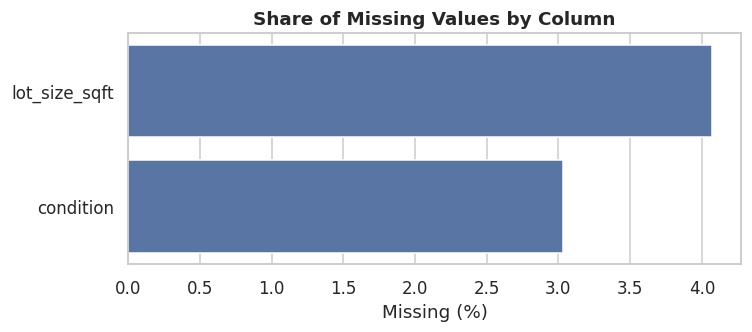

In [ ]:
missing = raw.isna().sum()
missing_pct = (missing / len(raw) * 100).round(2)
missing_table = pd.DataFrame({"missing_count": missing, "missing_percent": missing_pct})
missing_table = missing_table[missing_table["missing_count"] > 0]
display(missing_table)

fig, ax = plt.subplots(figsize=(7, 3.2))
sns.barplot(x=missing_table["missing_percent"], y=missing_table.index, ax=ax, color="#4C72B0")
ax.set_title("Share of Missing Values by Column")
ax.set_xlabel("Missing (%)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

**What we notice:** two columns have gaps (`lot_size_sqft` and `condition`), and the summary table shows suspiciously large values in `sqft`. We will deal with each of these in the next section.

## 5. Cleaning the Data

Good models start with honest data. We will handle three issues, one at a time.

| Issue | What we do | Why |
|---|---|---|
| Duplicate listings | Remove them | The same house counted twice would bias the model and leak between train and test |
| Data-entry typos | Detect with a statistical rule and remove | A 15,000 sq ft house priced like a small one is almost certainly a typing slip |
| Missing values | Leave for now, fill later inside the modelling pipeline | Filling them before the train/test split would let test information leak into training |

### 5.1 Removing duplicate listings

In [ ]:
df = raw.copy()
rows_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Rows before: {rows_before:,}")
print(f"Rows after : {len(df):,}")
print(f"Duplicates removed: {rows_before - len(df)}")

Rows before: 2,015
Rows after : 2,000
Duplicates removed: 15


### 5.2 Catching data-entry typos

A house's price per square foot varies, but only within a sensible range. A typo in `sqft` shows up as an extreme, unrealistically *low* price per square foot.

We use the **IQR rule** on the log of price per square foot: anything beyond 3 IQRs from the quartiles is treated as an extreme outlier (3 rather than the usual 1.5, so that we only remove clear mistakes and not merely unusual houses).

In [ ]:
df["log_ppsf"] = np.log(df["price"] / df["sqft"])

q1, q3 = df["log_ppsf"].quantile([0.25, 0.75])
iqr = q3 - q1
lower_fence, upper_fence = q1 - 3 * iqr, q3 + 3 * iqr

is_typo = (df["log_ppsf"] < lower_fence) | (df["log_ppsf"] > upper_fence)
print(f"Rows flagged as likely typos: {is_typo.sum()}")
df.loc[is_typo, ["listing_id", "neighborhood", "sqft", "bedrooms", "price"]]

Rows flagged as likely typos: 6


,listing_id,neighborhood,sqft,bedrooms,price
312,1927,Downtown,"15,900.00",2,"327,000.00"
349,1940,Downtown,"10,800.00",1,"243,000.00"
403,1262,Rural,"21,100.00",4,"255,000.00"
465,1377,Rural,"12,800.00",1,"127,000.00"
888,1907,Suburban,"23,200.00",4,"358,000.00"
1261,1815,Downtown,"15,500.00",3,"337,000.00"


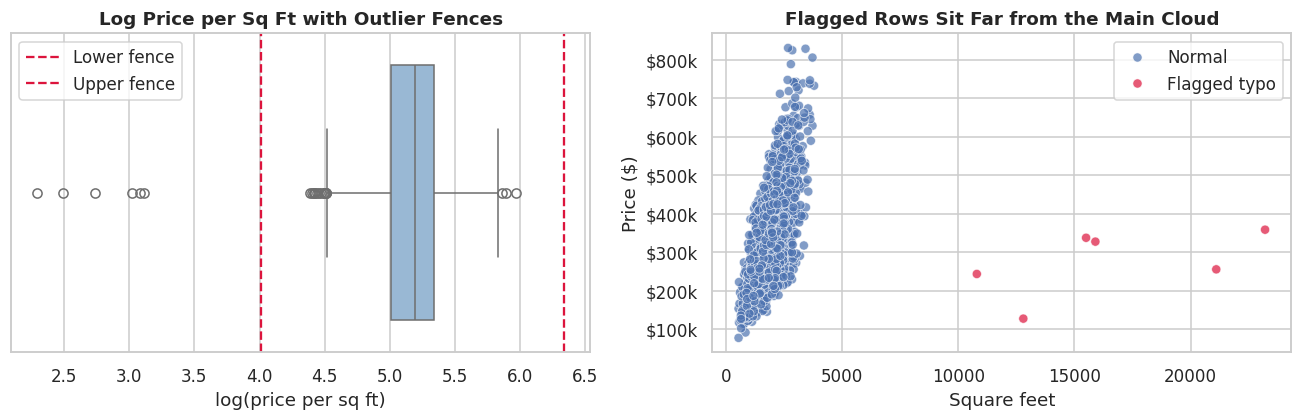

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(x=df["log_ppsf"], ax=axes[0], color="#8FB8DE")
axes[0].axvline(lower_fence, color="crimson", linestyle="--", label="Lower fence")
axes[0].axvline(upper_fence, color="crimson", linestyle="--", label="Upper fence")
axes[0].set_title("Log Price per Sq Ft with Outlier Fences")
axes[0].set_xlabel("log(price per sq ft)")
axes[0].legend()

sns.scatterplot(data=df, x="sqft", y="price", hue=is_typo.map({True: "Flagged typo", False: "Normal"}),
                palette={"Normal": "#4C72B0", "Flagged typo": "crimson"}, alpha=0.7, ax=axes[1])
axes[1].set_title("Flagged Rows Sit Far from the Main Cloud")
axes[1].set_xlabel("Square feet")
axes[1].set_ylabel("Price ($)")
axes[1].yaxis.set_major_formatter(lambda x, _: f"${x/1000:,.0f}k")
axes[1].legend(title="")

plt.tight_layout()
plt.show()

In [ ]:
df = df.loc[~is_typo].drop(columns="log_ppsf").reset_index(drop=True)
print(f"Clean dataset: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Largest house in the cleaned data: {df['sqft'].max():,.0f} sq ft")

Clean dataset: 1,994 rows x 11 columns
Largest house in the cleaned data: 3,800 sq ft


## 6. Exploring the Data Visually

Now that the data is tidy, let us get to know it. We start with the thing we want to predict: the price.

### 6.1 How are prices distributed?

House prices are usually right-skewed: lots of modest homes and a long tail of expensive ones. Taking the logarithm often makes such data more symmetric, which suits many models.

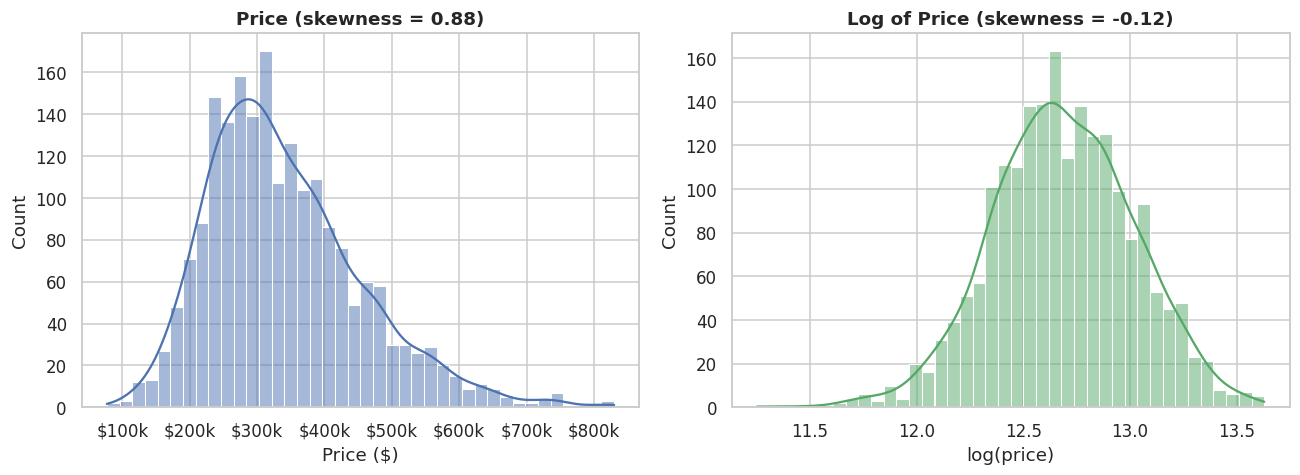

In [ ]:
df["log_price"] = np.log(df["price"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.histplot(df["price"], kde=True, bins=40, ax=axes[0], color="#4C72B0")
axes[0].set_title(f"Price (skewness = {stats.skew(df['price']):.2f})")
axes[0].set_xlabel("Price ($)")
axes[0].xaxis.set_major_formatter(lambda x, _: f"${x/1000:,.0f}k")

sns.histplot(df["log_price"], kde=True, bins=40, ax=axes[1], color="#55A868")
axes[1].set_title(f"Log of Price (skewness = {stats.skew(df['log_price']):.2f})")
axes[1].set_xlabel("log(price)")

plt.tight_layout()
plt.show()

### 6.2 Do neighbourhoods differ in price?

,count,median,mean,std
neighborhood,,,,
Rural,411,"260,000.00","269,892.94","75,574.34"
Downtown,405,"277,000.00","287,923.46","71,726.15"
Suburban,884,"346,000.00","352,341.63","94,018.67"
Lakeside,294,"477,500.00","480,166.67","130,181.77"


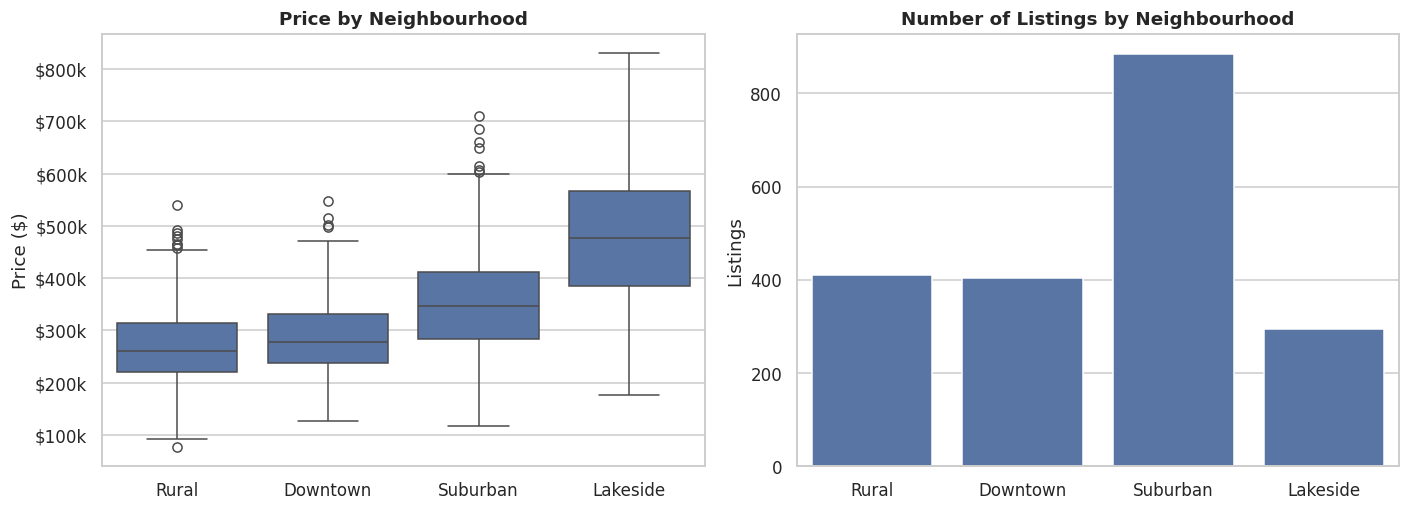

In [ ]:
order = df.groupby("neighborhood")["price"].median().sort_values().index

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

sns.boxplot(data=df, x="neighborhood", y="price", order=order, ax=axes[0])
axes[0].set_title("Price by Neighbourhood")
axes[0].set_xlabel("")
axes[0].set_ylabel("Price ($)")
axes[0].yaxis.set_major_formatter(lambda x, _: f"${x/1000:,.0f}k")

sns.countplot(data=df, x="neighborhood", order=order, ax=axes[1])
axes[1].set_title("Number of Listings by Neighbourhood")
axes[1].set_xlabel("")
axes[1].set_ylabel("Listings")

plt.tight_layout()
plt.show()

df.groupby("neighborhood")["price"].agg(["count", "median", "mean", "std"]).loc[order]

### 6.3 How does size relate to price?

The left chart uses raw values and the right one uses logarithms on both axes. If the right chart looks like a straighter line, then a model on the log scale will fit more naturally.

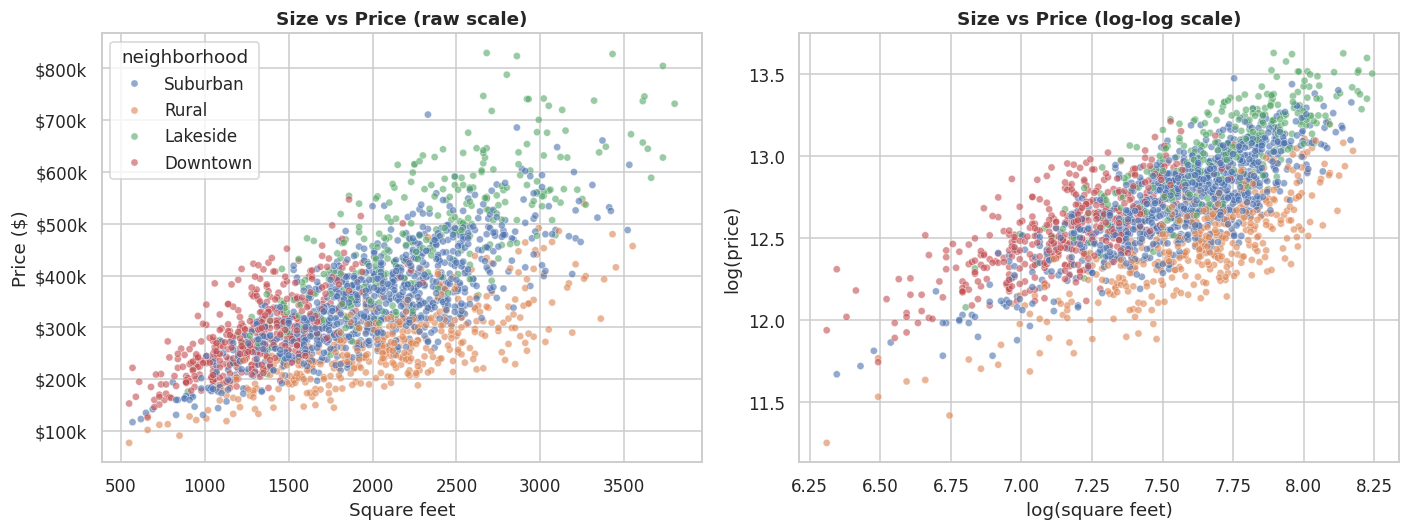

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(data=df, x="sqft", y="price", hue="neighborhood", alpha=0.6, s=22, ax=axes[0])
axes[0].set_title("Size vs Price (raw scale)")
axes[0].set_xlabel("Square feet")
axes[0].set_ylabel("Price ($)")
axes[0].yaxis.set_major_formatter(lambda x, _: f"${x/1000:,.0f}k")

sns.scatterplot(data=df, x=np.log(df["sqft"]), y=df["log_price"], hue=df["neighborhood"],
                alpha=0.6, s=22, ax=axes[1], legend=False)
axes[1].set_title("Size vs Price (log-log scale)")
axes[1].set_xlabel("log(square feet)")
axes[1].set_ylabel("log(price)")

plt.tight_layout()
plt.show()

### 6.4 Do the other features matter?

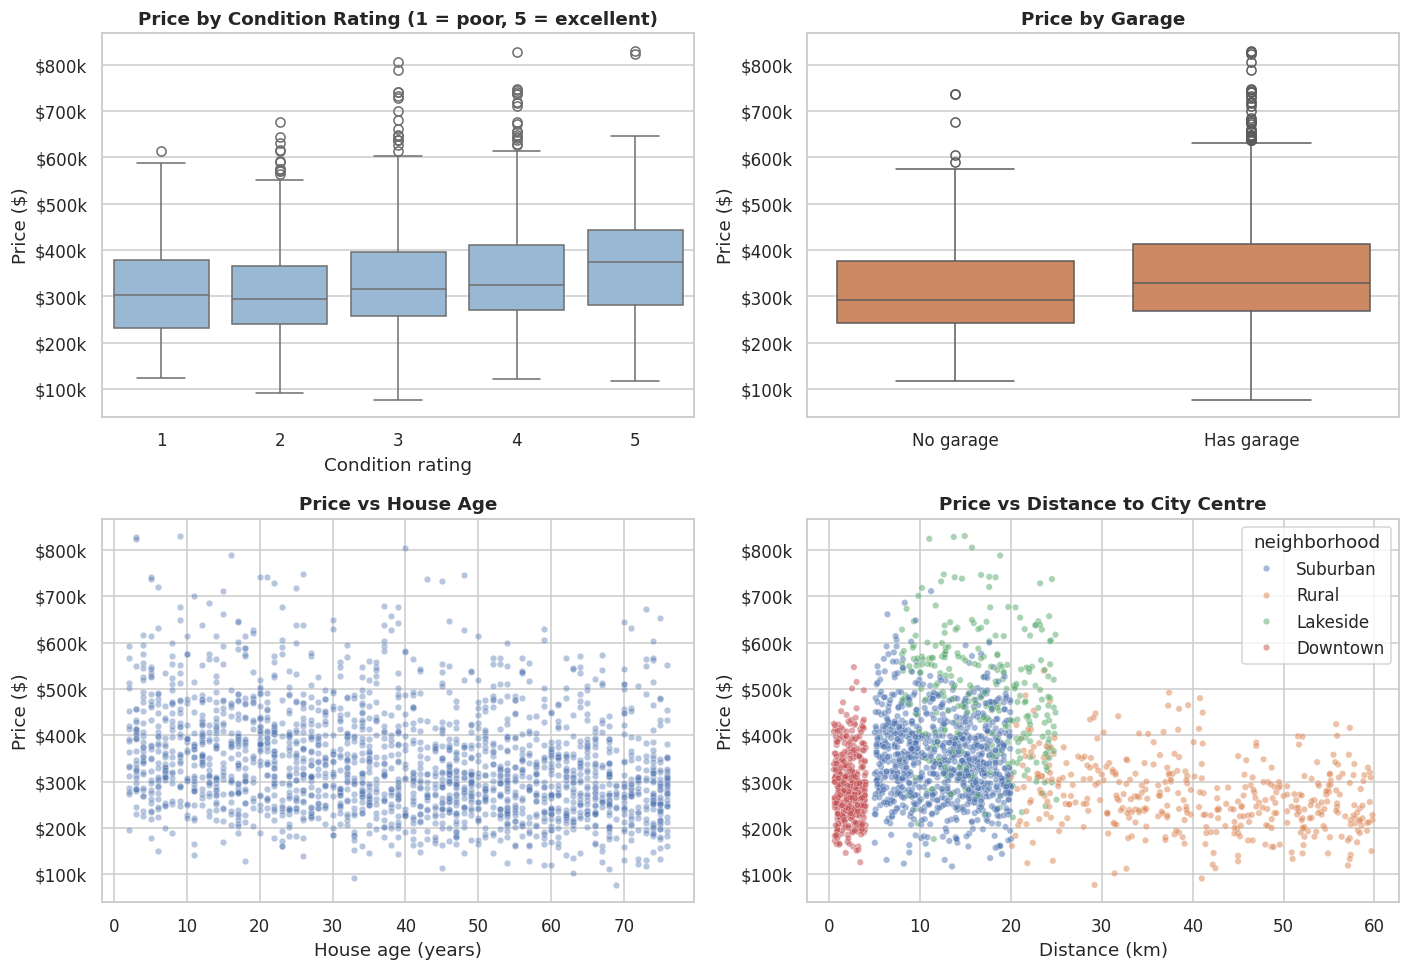

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

rated = df.dropna(subset=["condition"]).assign(condition=lambda d: d["condition"].astype(int))
sns.boxplot(data=rated, x="condition", y="price", ax=axes[0, 0], color="#8FB8DE")
axes[0, 0].set_title("Price by Condition Rating (1 = poor, 5 = excellent)")
axes[0, 0].set_xlabel("Condition rating")
axes[0, 0].set_ylabel("Price ($)")
axes[0, 0].yaxis.set_major_formatter(lambda x, _: f"${x/1000:,.0f}k")

sns.boxplot(data=df, x="has_garage", y="price", ax=axes[0, 1], color="#DD8452")
axes[0, 1].set_xticks([0, 1], ["No garage", "Has garage"])
axes[0, 1].set_title("Price by Garage")
axes[0, 1].set_xlabel("")
axes[0, 1].set_ylabel("Price ($)")
axes[0, 1].yaxis.set_major_formatter(lambda x, _: f"${x/1000:,.0f}k")

sns.scatterplot(data=df, x=CURRENT_YEAR - df["year_built"], y="price", alpha=0.4, s=18, ax=axes[1, 0])
axes[1, 0].set_title("Price vs House Age")
axes[1, 0].set_xlabel("House age (years)")
axes[1, 0].set_ylabel("Price ($)")
axes[1, 0].yaxis.set_major_formatter(lambda x, _: f"${x/1000:,.0f}k")

sns.scatterplot(data=df, x="distance_to_center_km", y="price", hue="neighborhood", alpha=0.5, s=18, ax=axes[1, 1])
axes[1, 1].set_title("Price vs Distance to City Centre")
axes[1, 1].set_xlabel("Distance (km)")
axes[1, 1].set_ylabel("Price ($)")
axes[1, 1].yaxis.set_major_formatter(lambda x, _: f"${x/1000:,.0f}k")

plt.tight_layout()
plt.show()

### 6.5 Which numbers move together?

A correlation heatmap gives a quick overview. We use Spearman correlation because it captures any steady upward or downward relationship, not just straight lines, and it is not thrown off by outliers.

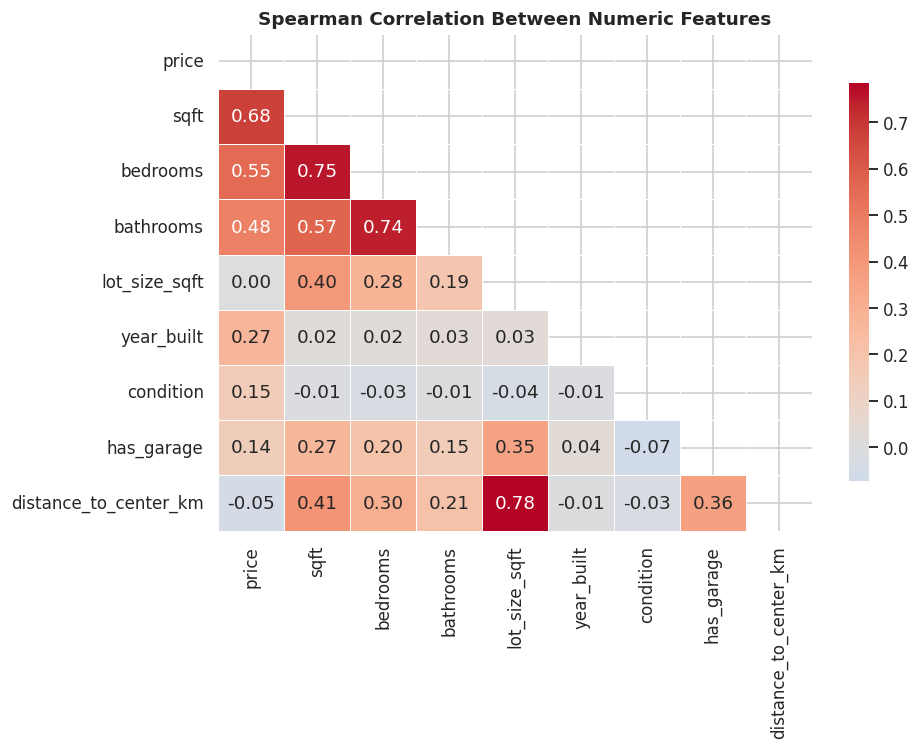

In [ ]:
corr_cols = ["price", "sqft", "bedrooms", "bathrooms", "lot_size_sqft", "year_built",
             "condition", "has_garage", "distance_to_center_km"]
corr = df[corr_cols].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Spearman Correlation Between Numeric Features")
plt.tight_layout()
plt.show()

**Reading the picture:** size (`sqft`), bedrooms and bathrooms are strongly linked to each other, which is natural because bigger houses have more rooms. Keep this in mind: strongly related features can confuse simple models, and we will measure that properly in section 8.

## 7. Testing Our Hunches Statistically

Charts suggest patterns, but a chart cannot tell us whether a pattern is real or just luck. Hypothesis tests can. In each test below we state the question, the null hypothesis (H0), pick a test that suits the data, and read the result.

We use a significance level of **α = 0.05**. A p-value below 0.05 means the data would be surprising if H0 were true, so we reject H0.

> These tests are exploratory. Running several tests on the same data raises the chance of a false alarm slightly, so p-values very close to 0.05 would deserve caution. As you will see, most of ours are nowhere near that line.

In [ ]:
ALPHA = 0.05

def verdict(p, alpha=ALPHA):
    # Plain-English reading of a p-value.
    if p < alpha:
        return f"p = {p:.4g} < {alpha}  ->  statistically significant, reject H0"
    return f"p = {p:.4g} >= {alpha}  ->  not significant, fail to reject H0"

### 7.1 Is price normally distributed?

**Why it matters:** many methods (and the way we read residuals later) work best when the quantity being modelled is roughly bell-shaped.

- **H0:** the values come from a normal distribution.
- **H1:** they do not.
- **Test:** Shapiro-Wilk, which is the standard, most powerful normality test for samples of this size.

Price         W = 0.9569   p = 7.789e-24 < 0.05  ->  statistically significant, reject H0
Log of price  W = 0.9978   p = 0.006561 < 0.05  ->  statistically significant, reject H0


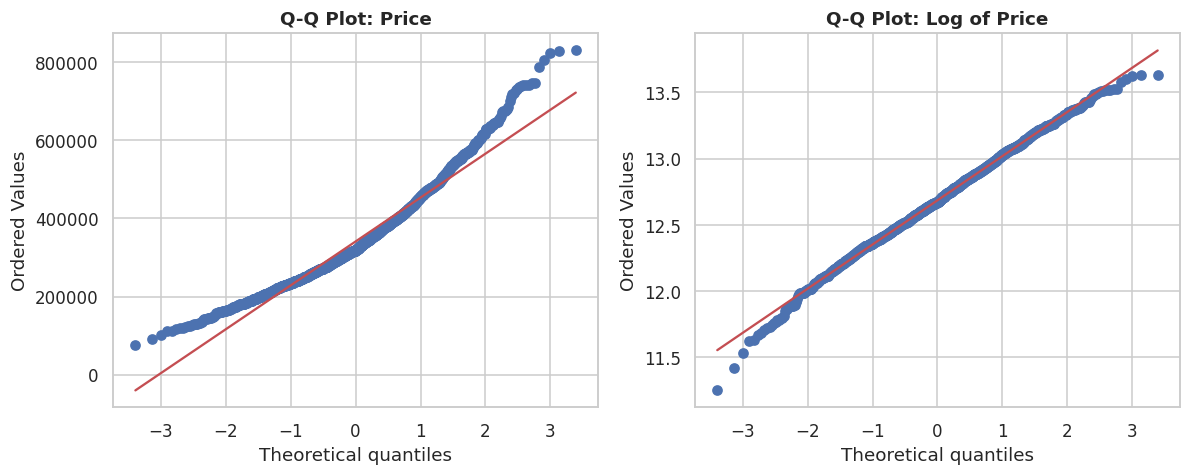

In [ ]:
for label, values in [("Price", df["price"]), ("Log of price", df["log_price"])]:
    w, p = stats.shapiro(values)
    print(f"{label:<13} W = {w:.4f}   {verdict(p)}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
stats.probplot(df["price"], dist="norm", plot=axes[0])
axes[0].set_title("Q-Q Plot: Price")
stats.probplot(df["log_price"], dist="norm", plot=axes[1])
axes[1].set_title("Q-Q Plot: Log of Price")
plt.tight_layout()
plt.show()

**Takeaway:** the Q-Q plot compares our data to a perfect bell curve; points hugging the red line mean "close to normal". Raw price bends away from the line in the upper tail (W is about 0.957), while the log of price sits much closer to it (W is about 0.998). That supports modelling the **log of price** instead of raw price.

With about 2,000 rows, Shapiro-Wilk can flag even tiny departures from normality, so we judge the Q-Q plot and skewness together with the p-value, not the p-value alone.

### 7.2 Is bigger really pricier?

- **H0:** there is no monotonic relationship between size and price (correlation = 0).
- **H1:** there is a relationship.
- **Tests:** Spearman (rank-based, no assumptions about shape) and Pearson on the log scale (measures straight-line strength after the transformation).

In [ ]:
rho, p_rho = stats.spearmanr(df["sqft"], df["price"])
r, p_r = stats.pearsonr(np.log(df["sqft"]), df["log_price"])

print(f"Spearman, sqft vs price          : rho = {rho:.3f}   {verdict(p_rho)}")
print(f"Pearson,  log(sqft) vs log(price): r   = {r:.3f}   {verdict(p_r)}")

Spearman, sqft vs price          : rho = 0.678   p = 3.265e-268 < 0.05  ->  statistically significant, reject H0
Pearson,  log(sqft) vs log(price): r   = 0.704   p = 6.738e-299 < 0.05  ->  statistically significant, reject H0


### 7.3 Do neighbourhoods really have different prices?

- **H0:** all four neighbourhoods have the same average log-price.
- **H1:** at least one neighbourhood differs.
- **Test:** one-way ANOVA. Before trusting it we check its equal-variance assumption with **Levene's test**, and we back it up with the rank-based **Kruskal-Wallis** test, which does not need normality.
- **If significant:** **Tukey's HSD** tells us *which* pairs differ, while controlling the false-alarm rate across all the comparisons.
- **Effect size:** eta-squared tells us how much of the price variation neighbourhood explains.

In [ ]:
names = list(order)
groups = [df.loc[df["neighborhood"] == g, "log_price"].to_numpy() for g in names]

lev_stat, lev_p = stats.levene(*groups)
f_stat, f_p = stats.f_oneway(*groups)
h_stat, h_p = stats.kruskal(*groups)

grand_mean = df["log_price"].mean()
ss_between = sum(len(g) * (g.mean() - grand_mean) ** 2 for g in groups)
ss_total = ((df["log_price"] - grand_mean) ** 2).sum()
eta_sq = ss_between / ss_total

print(f"Levene (equal variances) : W = {lev_stat:.3f}   {verdict(lev_p)}")
print(f"One-way ANOVA            : F = {f_stat:.2f}   {verdict(f_p)}")
print(f"Kruskal-Wallis           : H = {h_stat:.2f}   {verdict(h_p)}")
print(f"Eta-squared (effect size): {eta_sq:.3f}  ({eta_sq:.1%} of log-price variation is explained by neighbourhood)")

Levene (equal variances) : W = 2.219   p = 0.08403 >= 0.05  ->  not significant, fail to reject H0
One-way ANOVA            : F = 295.96   p = 7.587e-159 < 0.05  ->  statistically significant, reject H0
Kruskal-Wallis           : H = 602.26   p = 3.257e-130 < 0.05  ->  statistically significant, reject H0
Eta-squared (effect size): 0.309  (30.9% of log-price variation is explained by neighbourhood)


In [ ]:
tukey = stats.tukey_hsd(*groups)
tukey_table = pd.DataFrame(
    [
        {
            "Group A": names[i],
            "Group B": names[j],
            "Mean diff (A - B), log scale": tukey.statistic[i, j],
            "p-value": f"{tukey.pvalue[i, j]:.2e}",
            "Significant?": "Yes" if tukey.pvalue[i, j] < ALPHA else "No",
        }
        for i in range(len(names)) for j in range(i + 1, len(names))
    ]
)
tukey_table

,Group A,Group B,"Mean diff (A - B), log scale",p-value,Significant?
0,Rural,Downtown,-0.07,7.08e-04,Yes
1,Rural,Suburban,-0.27,0.00e+00,Yes
2,Rural,Lakeside,-0.58,0.00e+00,Yes
3,Downtown,Suburban,-0.20,0.00e+00,Yes
4,Downtown,Lakeside,-0.50,0.00e+00,Yes
5,Suburban,Lakeside,-0.31,0.00e+00,Yes


**Takeaway:** Levene's test found no evidence of unequal variances, so ANOVA's main assumption is reasonable here. ANOVA and Kruskal-Wallis agree that neighbourhoods differ, and Tukey's HSD shows that every pair of neighbourhoods differs, with Lakeside the most expensive and Rural the cheapest. Because two different tests reach the same conclusion, the result does not depend on which one we chose. Neighbourhood explains roughly a third of the variation in log-price, which is a large effect.

### 7.4 Do houses with a garage sell for more?

- **H0:** houses with and without a garage have the same mean log-price.
- **H1:** the means differ.
- **Test:** Welch's t-test, which does not assume equal variances. We add **Cohen's d** to measure how big the difference is.

A caution before we start: garages are not spread evenly across neighbourhoods (see 7.5), so this raw comparison mixes the effect of the garage with the effect of the location. The model in later sections separates the two.

In [ ]:
with_garage = df.loc[df["has_garage"] == 1, "log_price"]
no_garage = df.loc[df["has_garage"] == 0, "log_price"]

t_stat, t_p = stats.ttest_ind(with_garage, no_garage, equal_var=False)

pooled_sd = np.sqrt(((len(with_garage) - 1) * with_garage.var() + (len(no_garage) - 1) * no_garage.var())
                    / (len(with_garage) + len(no_garage) - 2))
cohens_d = (with_garage.mean() - no_garage.mean()) / pooled_sd

print(f"Mean log-price with garage    : {with_garage.mean():.3f}   (n = {len(with_garage)})")
print(f"Mean log-price without garage : {no_garage.mean():.3f}   (n = {len(no_garage)})")
print(f"Welch t-test                  : t = {t_stat:.2f}   {verdict(t_p)}")
print(f"Cohen's d                     : {cohens_d:.2f}  (0.2 small, 0.5 medium, 0.8 large)")

Mean log-price with garage    : 12.708   (n = 1541)
Mean log-price without garage : 12.607   (n = 453)
Welch t-test                  : t = 6.06   p = 2.149e-09 < 0.05  ->  statistically significant, reject H0
Cohen's d                     : 0.31  (0.2 small, 0.5 medium, 0.8 large)


### 7.5 Are garages equally common in every neighbourhood?

This explains the caution in 7.4.

- **H0:** having a garage is independent of the neighbourhood.
- **H1:** the two are associated.
- **Test:** chi-square test of independence, with **Cramér's V** as the effect size.


Smallest expected count in any cell: 66.8  (should be at least 5 for the test to be valid)
Chi-square = 475.79, dof = 3   p = 8.397e-103 < 0.05  ->  statistically significant, reject H0
Cramer's V = 0.488  (0.1 small, 0.3 medium, 0.5 large)


has_garage,Has garage,No garage
neighborhood,,
Downtown,150,255
Lakeside,254,40
Rural,379,32
Suburban,758,126


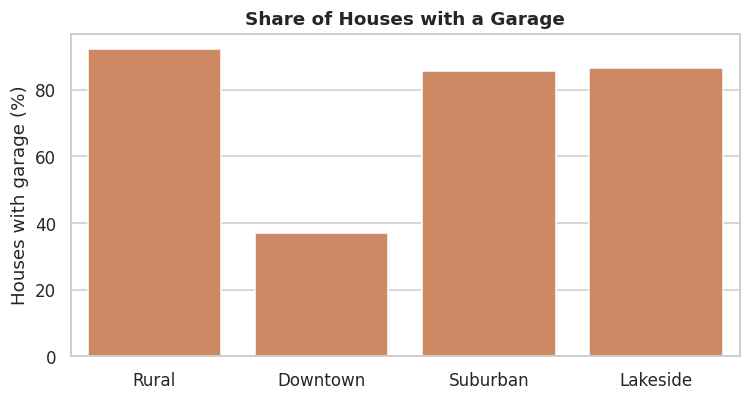

In [ ]:
table = pd.crosstab(df["neighborhood"], df["has_garage"].map({0: "No garage", 1: "Has garage"}))
chi2, chi_p, dof, expected = stats.chi2_contingency(table)
cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))

display(table)
print(f"\nSmallest expected count in any cell: {expected.min():.1f}  (should be at least 5 for the test to be valid)")
print(f"Chi-square = {chi2:.2f}, dof = {dof}   {verdict(chi_p)}")
print(f"Cramer's V = {cramers_v:.3f}  (0.1 small, 0.3 medium, 0.5 large)")

garage_share = df.groupby("neighborhood")["has_garage"].mean().loc[order].mul(100)
fig, ax = plt.subplots(figsize=(7, 3.8))
sns.barplot(x=garage_share.index, y=garage_share.values, ax=ax, color="#DD8452")
ax.set_title("Share of Houses with a Garage")
ax.set_xlabel("")
ax.set_ylabel("Houses with garage (%)")
plt.tight_layout()
plt.show()

### 7.6 Does a better condition rating go with a higher price?

Condition is an *ordered* rating (1 to 5), so a rank-based test is the right tool.

- **H0:** no monotonic relationship between condition and price.
- **H1:** there is one.
- **Test:** Spearman rank correlation, on rows where the rating is available.

In [ ]:
known = df.dropna(subset=["condition"])
rho_c, p_c = stats.spearmanr(known["condition"], known["log_price"])
print(f"Spearman, condition vs log(price): rho = {rho_c:.3f}   {verdict(p_c)}")
print(f"Rows used: {len(known):,} (rows with a missing rating are skipped)")

Spearman, condition vs log(price): rho = 0.150   p = 3.16e-11 < 0.05  ->  statistically significant, reject H0
Rows used: 1,934 (rows with a missing rating are skipped)


## 8. Preparing Features for Modelling

The tests above told us what to do:

- Model **log(price)** rather than raw price, because it is much closer to normal.
- Use the **log of size and lot size**, so the relationship with price is closer to a straight line.
- Turn `year_built` into **house age**, which is easier to interpret.
- Encode `neighborhood` as dummy columns (this happens inside the pipeline).
- Keep an eye on **multicollinearity**, because size, bedrooms and bathrooms move together.

All engineered features come from a single function. That way new listings can be prepared in exactly the same way later.

In [ ]:
def add_features(frame):
    # Create the model-ready features from the raw listing columns.
    out = frame.copy()
    out["log_sqft"] = np.log(out["sqft"])
    out["log_lot_size"] = np.log(out["lot_size_sqft"])      # stays NaN where lot size is missing
    out["house_age"] = CURRENT_YEAR - out["year_built"]
    return out

df = add_features(df)
df[["sqft", "log_sqft", "lot_size_sqft", "log_lot_size", "year_built", "house_age"]].head()

,sqft,log_sqft,lot_size_sqft,log_lot_size,year_built,house_age
0,"1,930.00",7.57,"4,920.00",8.50,1950,76
1,"1,640.00",7.40,"18,160.00",9.81,1976,50
2,"3,160.00",8.06,"6,760.00",8.82,1988,38
3,"1,370.00",7.22,"1,960.00",7.58,1960,66
4,"2,690.00",7.90,"28,070.00",10.24,2023,3


### 8.1 Checking for multicollinearity with VIF

The **Variance Inflation Factor (VIF)** tells us how well each feature can be predicted from the others. A common rule of thumb: below 5 is fine, 5 to 10 deserves a look, above 10 is a serious problem.

In [ ]:
numeric_features = ["log_sqft", "log_lot_size", "bedrooms", "bathrooms", "house_age",
                    "condition", "has_garage", "distance_to_center_km"]

vif_data = df[numeric_features].dropna().astype(float)
vif_values = {}
for col in numeric_features:
    others = vif_data.drop(columns=col)
    r2 = LinearRegression().fit(others, vif_data[col]).score(others, vif_data[col])
    vif_values[col] = 1 / (1 - r2)

vif_table = pd.Series(vif_values, name="VIF").sort_values(ascending=False).to_frame()
vif_table["Verdict"] = np.where(vif_table["VIF"] < 5, "Fine", np.where(vif_table["VIF"] < 10, "Look closer", "Problem"))
vif_table

,VIF,Verdict
bedrooms,3.43,Fine
log_lot_size,3.20,Fine
distance_to_center_km,2.88,Fine
log_sqft,2.42,Fine
bathrooms,2.24,Fine
has_garage,1.18,Fine
condition,1.01,Fine
house_age,1.00,Fine


All VIF values should sit comfortably below 5. That means we can keep every feature, and linear models will give stable, interpretable results.

## 9. Splitting the Data and Building the Pipeline

### 9.1 Train and test sets

We hold back 20% of the houses as a **test set**. The model never sees them while learning or tuning. They only come out at the very end, for an honest final grade.

In [ ]:
categorical_features = ["neighborhood"]
feature_columns = numeric_features + categorical_features

X = df[feature_columns]
y = df["log_price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE)

print(f"Training houses: {len(X_train):,}")
print(f"Test houses    : {len(X_test):,}")

Training houses: 1,595
Test houses    : 399


### 9.2 A pipeline that prevents data leakage

All preprocessing lives inside a **pipeline**, so that it is learned from the training data only:

- Numeric columns: fill missing values with the **median**, then **standardise** (mean 0, spread 1).
- Neighbourhood: **one-hot encode** (one column per neighbourhood, minus one to avoid redundancy).

Each model gets its own fresh copy of the preprocessing step.

In [ ]:
def make_preprocessor():
    numeric_steps = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    return ColumnTransformer([
        ("numeric", numeric_steps, numeric_features),
        ("categorical", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_features),
    ])

def make_pipeline(model):
    return Pipeline([("prep", make_preprocessor()), ("model", model)])

## 10. Comparing Candidate Models

We try four models, from simple to flexible:

| Model | Idea |
|---|---|
| Linear Regression | The classic baseline: price is a weighted sum of features |
| Ridge Regression | Linear regression with a small penalty that keeps weights tame |
| Random Forest | Many decision trees voting together |
| Gradient Boosting | Trees built one after another, each fixing the last one's mistakes |

To compare them fairly, we use **5-fold cross-validation** on the training set: the data is split into five parts, each part takes a turn as the mini test set, and we average the scores. Errors are measured on the log scale, where an RMSE of 0.10 means a typical miss of roughly 10%.

In [ ]:
candidates = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
}

kfold = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"rmse": "neg_root_mean_squared_error", "r2": "r2"}

rows = []
for name, model in candidates.items():
    scores = cross_validate(make_pipeline(model), X_train, y_train, cv=kfold, scoring=scoring)
    rows.append({
        "Model": name,
        "CV RMSE (log scale)": -scores["test_rmse"].mean(),
        "RMSE std": scores["test_rmse"].std(),
        "CV R2": scores["test_r2"].mean(),
    })

cv_table = pd.DataFrame(rows).set_index("Model").sort_values("CV RMSE (log scale)")
cv_table

,CV RMSE (log scale),RMSE std,CV R2
Model,,,
Linear Regression,0.12,0.01,0.87
Ridge Regression,0.12,0.01,0.87
Gradient Boosting,0.13,0.01,0.85
Random Forest,0.14,0.00,0.82


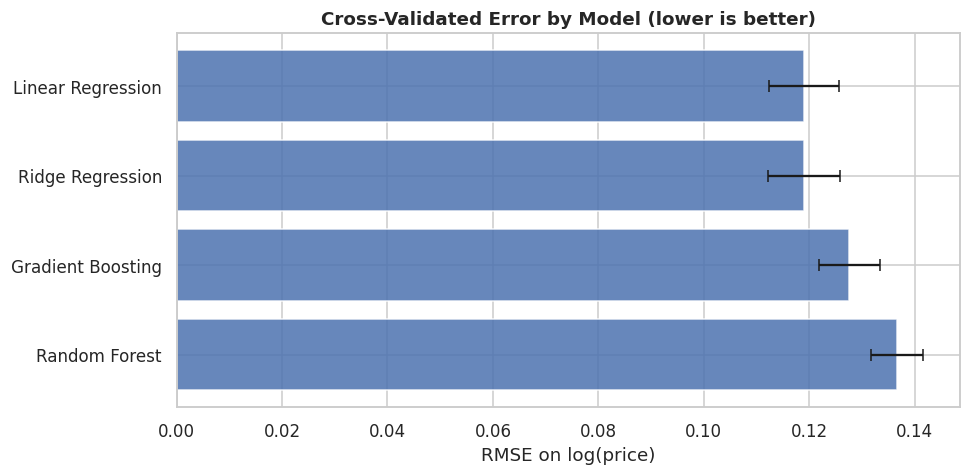

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(cv_table.index, cv_table["CV RMSE (log scale)"], xerr=cv_table["RMSE std"],
        color="#4C72B0", alpha=0.85, capsize=4)
ax.invert_yaxis()
ax.set_title("Cross-Validated Error by Model (lower is better)")
ax.set_xlabel("RMSE on log(price)")
plt.tight_layout()
plt.show()

## 11. Tuning the Best Contender

Tree-based models have settings (hyperparameters) that change how they learn. Instead of guessing, we let **grid search** try every combination from a small menu, scoring each with 5-fold cross-validation on the training data only.

We tune Gradient Boosting, the most flexible of our models, to give the non-linear approach its best shot.

In [ ]:
param_grid = {
    "model__n_estimators": [100, 200, 400],
    "model__learning_rate": [0.03, 0.1],
    "model__max_depth": [2, 3],
}

grid = GridSearchCV(
    make_pipeline(GradientBoostingRegressor(random_state=RANDOM_STATE)),
    param_grid, cv=kfold, scoring="neg_root_mean_squared_error", n_jobs=-1,
)
grid.fit(X_train, y_train)

print("Best settings found:")
for k, v in grid.best_params_.items():
    print(f"  {k.replace('model__', '')}: {v}")
print(f"\nBest CV RMSE (log scale): {-grid.best_score_:.4f}")

Best settings found:
  learning_rate: 0.1
  max_depth: 2
  n_estimators: 200

Best CV RMSE (log scale): 0.1240


### 11.1 Choosing the winner

We now put the tuned model next to the others and pick the model with the lowest cross-validated error. The test set is still untouched, so this choice is not influenced by it.

In [ ]:
final_table = cv_table[["CV RMSE (log scale)"]].copy()
final_table.loc["Gradient Boosting (tuned)"] = -grid.best_score_
final_table = final_table.sort_values("CV RMSE (log scale)")
display(final_table)

winner_name = final_table.index[0]
print(f"\nWinner on cross-validation: {winner_name}")


Winner on cross-validation: Linear Regression


,CV RMSE (log scale)
Model,
Linear Regression,0.12
Ridge Regression,0.12
Gradient Boosting (tuned),0.12
Gradient Boosting,0.13
Random Forest,0.14


In [ ]:
# Build every model we may need, trained on the training set only.
models_for_test = {
    "Linear Regression": make_pipeline(LinearRegression()),
    "Ridge Regression": make_pipeline(Ridge(alpha=1.0)),
    "Random Forest": make_pipeline(RandomForestRegressor(n_estimators=300, min_samples_leaf=3,
                                                         random_state=RANDOM_STATE, n_jobs=-1)),
    "Gradient Boosting": make_pipeline(GradientBoostingRegressor(random_state=RANDOM_STATE)),
    "Gradient Boosting (tuned)": grid.best_estimator_,
}
for name in ["Linear Regression", "Ridge Regression", "Random Forest", "Gradient Boosting"]:
    models_for_test[name].fit(X_train, y_train)

final_model = models_for_test[winner_name]
print(f"Final model: {winner_name}")

Final model: Linear Regression


## 12. The Final Exam: Unseen Houses

This is the moment of truth. The chosen model predicts prices for the 20% of houses it has never seen. Since it works on the log scale, we convert predictions back to dollars with `exp()`.

In [ ]:
pred_log = final_model.predict(X_test)
pred_price = np.exp(pred_log)
actual_price = np.exp(y_test.to_numpy())

mae = mean_absolute_error(actual_price, pred_price)
rmse = np.sqrt(mean_squared_error(actual_price, pred_price))
r2 = r2_score(actual_price, pred_price)
mape = np.mean(np.abs(pred_price - actual_price) / actual_price) * 100

print(f"Model: {winner_name}")
print(f"R-squared : {r2:.3f}   (share of price variation explained)")
print(f"MAE       : ${mae:,.0f}   (average miss)")
print(f"RMSE      : ${rmse:,.0f}   (typical miss, big errors weigh more)")
print(f"MAPE      : {mape:.1f}%   (average miss as a share of the true price)")

Model: Linear Regression
R-squared : 0.883   (share of price variation explained)
MAE       : $34,027   (average miss)
RMSE      : $43,397   (typical miss, big errors weigh more)
MAPE      : 10.1%   (average miss as a share of the true price)


### 12.1 How sure are we about these numbers?

A single test score is just one sample. **Bootstrapping** re-draws the test houses with replacement many times and recomputes the score, which gives an honest confidence interval.

In [ ]:
boot_rng = np.random.default_rng(RANDOM_STATE)
boot_mae, boot_r2 = [], []
for _ in range(2000):
    idx = boot_rng.integers(0, len(actual_price), len(actual_price))
    boot_mae.append(mean_absolute_error(actual_price[idx], pred_price[idx]))
    boot_r2.append(r2_score(actual_price[idx], pred_price[idx]))

mae_lo, mae_hi = np.percentile(boot_mae, [2.5, 97.5])
r2_lo, r2_hi = np.percentile(boot_r2, [2.5, 97.5])
print(f"MAE 95% confidence interval: ${mae_lo:,.0f} to ${mae_hi:,.0f}")
print(f"R2  95% confidence interval: {r2_lo:.3f} to {r2_hi:.3f}")

MAE 95% confidence interval: $31,378 to $36,811
R2  95% confidence interval: 0.859 to 0.902


### 12.2 Predicted vs actual prices

If the model were perfect, every dot would sit exactly on the dashed diagonal line.

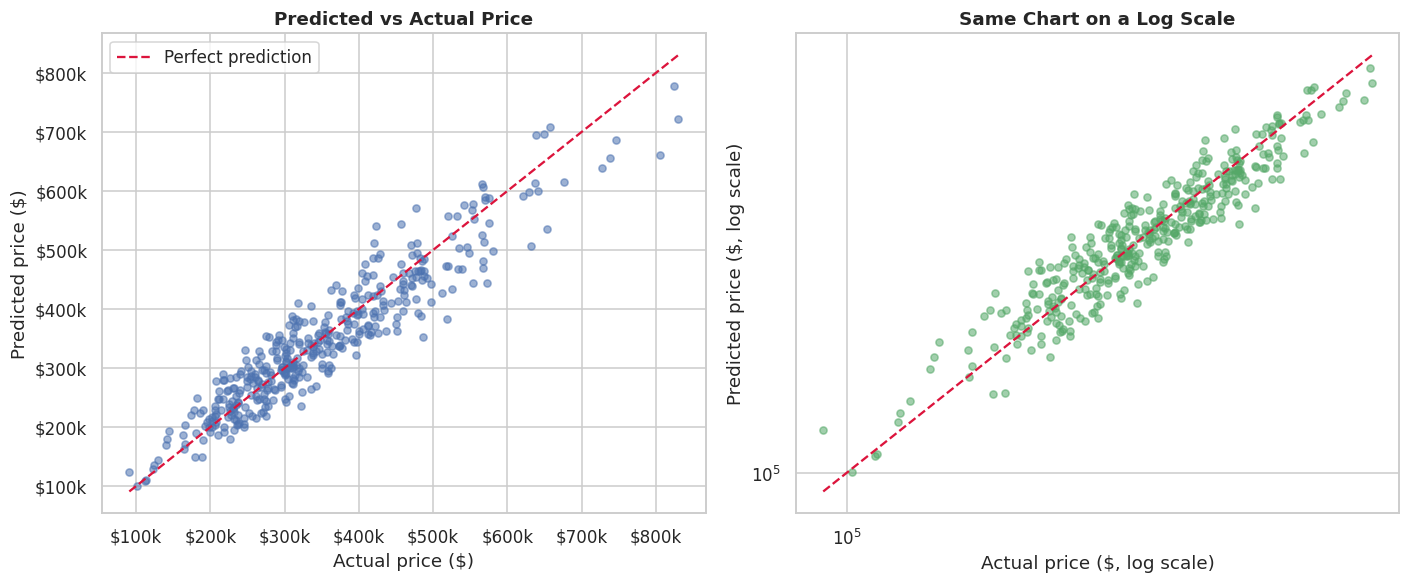

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

axes[0].scatter(actual_price, pred_price, alpha=0.55, s=22, color="#4C72B0")
lims = [min(actual_price.min(), pred_price.min()), max(actual_price.max(), pred_price.max())]
axes[0].plot(lims, lims, "--", color="crimson", label="Perfect prediction")
axes[0].set_title("Predicted vs Actual Price")
axes[0].set_xlabel("Actual price ($)")
axes[0].set_ylabel("Predicted price ($)")
axes[0].xaxis.set_major_formatter(lambda x, _: f"${x/1000:,.0f}k")
axes[0].yaxis.set_major_formatter(lambda x, _: f"${x/1000:,.0f}k")
axes[0].legend()

axes[1].scatter(actual_price, pred_price, alpha=0.55, s=22, color="#55A868")
axes[1].plot(lims, lims, "--", color="crimson")
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_title("Same Chart on a Log Scale")
axes[1].set_xlabel("Actual price ($, log scale)")
axes[1].set_ylabel("Predicted price ($, log scale)")

plt.tight_layout()
plt.show()

### 12.3 Is the winner really better than a simple baseline?

A fancy model has to earn its place. We compare the chosen model's test errors against plain Linear Regression on the *same* houses with a **Wilcoxon signed-rank test**. It is a paired test, because both models predict the same test houses, and it does not need the errors to be normal.

- **H0:** the two models have the same typical error.
- **H1:** their typical errors differ.

In [ ]:
baseline_name = "Linear Regression"
if winner_name == baseline_name:
    baseline_name = "Gradient Boosting (tuned)"   # compare the winner with the most flexible alternative instead

err_winner = np.abs(models_for_test[winner_name].predict(X_test) - y_test.to_numpy())
err_other = np.abs(models_for_test[baseline_name].predict(X_test) - y_test.to_numpy())

w_stat, w_p = stats.wilcoxon(err_winner, err_other)
print(f"Winner   : {winner_name}  (median abs. error on log scale = {np.median(err_winner):.4f})")
print(f"Compared : {baseline_name}  (median abs. error on log scale = {np.median(err_other):.4f})")
print(f"Wilcoxon signed-rank: W = {w_stat:.0f}   {verdict(w_p)}")

Winner   : Linear Regression  (median abs. error on log scale = 0.0848)
Compared : Gradient Boosting (tuned)  (median abs. error on log scale = 0.0894)
Wilcoxon signed-rank: W = 36645   p = 0.1579 >= 0.05  ->  not significant, fail to reject H0


## 13. Checking the Model's Assumptions

A model with a good score can still be misleading if its mistakes follow a pattern. We inspect the **residuals** (actual minus predicted, on the log scale). In a healthy model they should:

1. Be centred on zero, with no leftover trend.
2. Have the same spread for cheap and expensive houses (constant variance).
3. Be roughly bell-shaped.

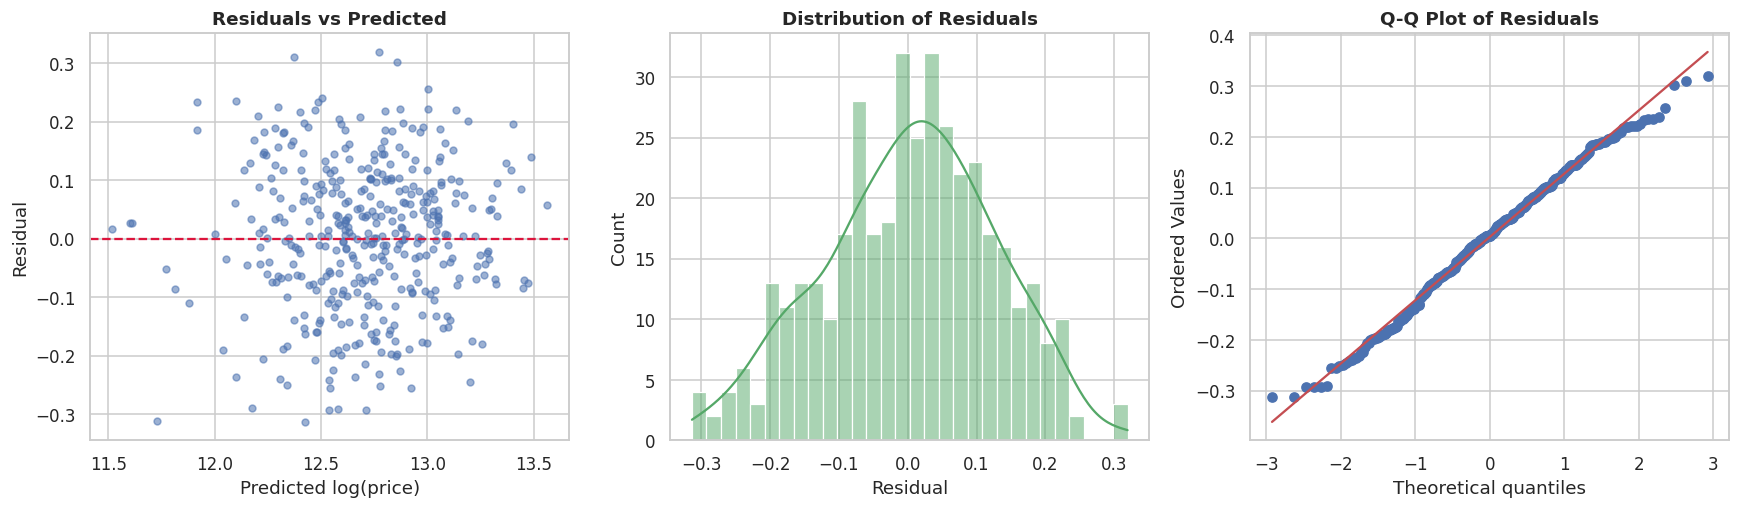

In [ ]:
residuals = y_test.to_numpy() - pred_log

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

axes[0].scatter(pred_log, residuals, alpha=0.55, s=20, color="#4C72B0")
axes[0].axhline(0, color="crimson", linestyle="--")
axes[0].set_title("Residuals vs Predicted")
axes[0].set_xlabel("Predicted log(price)")
axes[0].set_ylabel("Residual")

sns.histplot(residuals, kde=True, bins=30, ax=axes[1], color="#55A868")
axes[1].set_title("Distribution of Residuals")
axes[1].set_xlabel("Residual")

stats.probplot(residuals, dist="norm", plot=axes[2])
axes[2].set_title("Q-Q Plot of Residuals")

plt.tight_layout()
plt.show()

In [ ]:
# 1. Are residuals centred on zero?  One-sample t-test against 0.
t_res, p_mean = stats.ttest_1samp(residuals, 0)
print(f"Mean residual = {residuals.mean():+.4f}")
print(f"  One-sample t-test (H0: mean = 0)          : {verdict(p_mean)}")

# 2. Is the spread constant?  Rank correlation between |residual| and the prediction.
rho_h, p_h = stats.spearmanr(np.abs(residuals), pred_log)
print(f"\nSpearman, |residual| vs prediction: rho = {rho_h:+.3f}")
print(f"  (H0: spread does not change with price)   : {verdict(p_h)}")

# 3. Are residuals roughly normal?
w_res, p_norm = stats.shapiro(residuals)
print(f"\nShapiro-Wilk on residuals: W = {w_res:.4f}")
print(f"  (H0: residuals are normal)                : {verdict(p_norm)}")

Mean residual = +0.0028
  One-sample t-test (H0: mean = 0)          : p = 0.6483 >= 0.05  ->  not significant, fail to reject H0

Spearman, |residual| vs prediction: rho = -0.091
  (H0: spread does not change with price)   : p = 0.06951 >= 0.05  ->  not significant, fail to reject H0

Shapiro-Wilk on residuals: W = 0.9928
  (H0: residuals are normal)                : p = 0.05201 >= 0.05  ->  not significant, fail to reject H0


**How to read this:** the one-sample t-test checks for systematic over- or under-prediction. The Spearman check looks for a funnel shape in the residual plot, meaning errors that grow with price. Shapiro-Wilk checks the bell shape.

In our run none of the three checks rejects its H0: the mean residual is essentially zero, and the spread and shape look healthy. Two of the p-values (about 0.07 and 0.05) sit close to the 0.05 line, so we do not over-interpret them. The plots agree: no funnel, no curve, and a Q-Q plot that hugs the line.

## 14. What Actually Drives House Prices?

**Permutation importance** answers a simple question: if we scramble one feature's values at random, how much worse do the predictions get? The bigger the drop, the more the model relies on that feature. We run it on the test set, so it reflects what matters for unseen houses.

,feature,importance,std
0,log_sqft,1.05,0.05
1,neighborhood,0.40,0.03
2,house_age,0.11,0.01
3,distance_to_center_km,0.09,0.01
4,condition,0.07,0.01
5,log_lot_size,0.02,0.00
6,bathrooms,0.01,0.00
7,has_garage,0.00,0.00
8,bedrooms,0.00,0.00


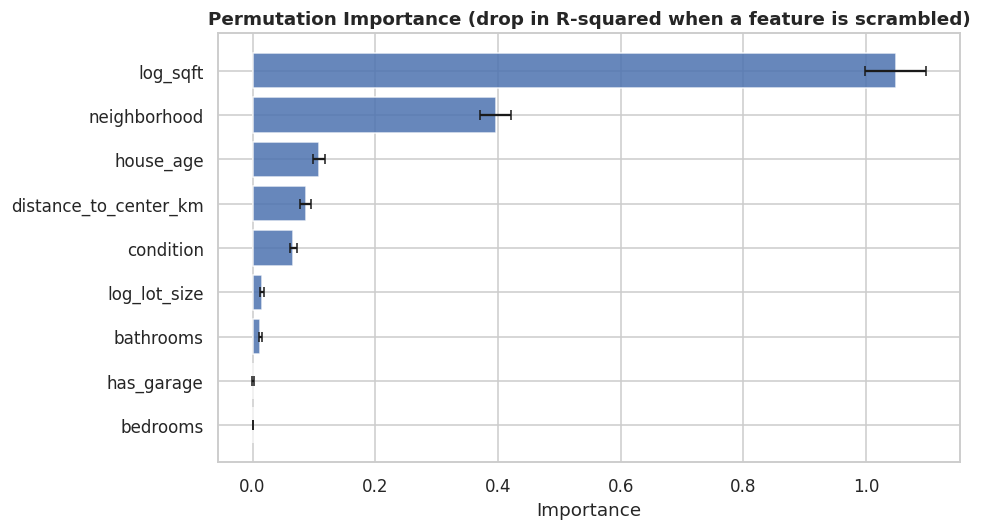

In [ ]:
perm = permutation_importance(final_model, X_test, y_test, n_repeats=20,
                              random_state=RANDOM_STATE, scoring="r2", n_jobs=-1)

importance = (pd.DataFrame({"feature": X_test.columns,
                            "importance": perm.importances_mean,
                            "std": perm.importances_std})
              .sort_values("importance", ascending=True))

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(importance["feature"], importance["importance"], xerr=importance["std"],
        color="#4C72B0", alpha=0.85, capsize=3)
ax.set_title("Permutation Importance (drop in R-squared when a feature is scrambled)")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

importance.sort_values("importance", ascending=False).reset_index(drop=True)

**Reading the chart:** size and neighbourhood dominate, followed by house age, distance to the centre and condition. `bedrooms` and `has_garage` score close to zero, but that does not mean they are worthless on their own. Bedrooms are largely captured by size and bathrooms (see the VIF table), so scrambling bedrooms barely hurts when size is still available. Permutation importance measures *unique* contribution, which is a useful nuance whenever features are correlated.

## 15. Trying It on a Brand-New House

Finally, let us use the model the way a real user would: describe a house, get a price. The new listing goes through the same `add_features` function as the training data.

In [ ]:
new_house = pd.DataFrame([{
    "neighborhood": "Suburban",
    "sqft": 2200,
    "bedrooms": 4,
    "bathrooms": 3,
    "year_built": 2008,
    "lot_size_sqft": 7500,
    "has_garage": 1,
    "condition": 4,
    "distance_to_center_km": 12.0,
}])

new_features = add_features(new_house)[feature_columns]
estimate = float(np.exp(final_model.predict(new_features))[0])

# A rough range: +/- the typical (RMSE) error on the log scale, converted back to dollars.
log_rmse = float(np.sqrt(np.mean(residuals ** 2)))
low, high = estimate * np.exp(-log_rmse), estimate * np.exp(log_rmse)

print(f"Estimated price: ${estimate:,.0f}")
print(f"Likely range   : ${low:,.0f}  to  ${high:,.0f}  (about one typical error either side)")

Estimated price: $451,813
Likely range   : $398,998  to  $511,618  (about one typical error either side)


## 16. Saving Our Work

We save the cleaned dataset and the trained model, so the model can be reused without retraining.

In [ ]:
os.makedirs("data", exist_ok=True)
os.makedirs("models", exist_ok=True)

df.drop(columns=["log_price", "log_sqft", "log_lot_size", "house_age"]).to_csv("data/housing_clean.csv", index=False)
joblib.dump(final_model, "models/house_price_model.joblib")

print("Saved: data/housing_clean.csv")
print("Saved: models/house_price_model.joblib")
print("\nTo reuse the model later:")
print("  model = joblib.load('models/house_price_model.joblib')")
print("  price = np.exp(model.predict(add_features(new_listing)[feature_columns]))")

Saved: data/housing_clean.csv
Saved: models/house_price_model.joblib

To reuse the model later:
  model = joblib.load('models/house_price_model.joblib')
  price = np.exp(model.predict(add_features(new_listing)[feature_columns]))


## 17. Conclusions, Limitations and Next Steps


### What we found

**About the data**

- After removing 15 duplicate listings and 6 data-entry typos, we kept 1,994 clean listings. Missing lot sizes and condition ratings were filled inside the pipeline, so nothing leaked from the test set.
- Raw prices are right-skewed. The log of price is far closer to a normal distribution, so we modelled `log(price)`.

**About the statistics**

- Size is strongly related to price (Spearman rho about 0.68), and the relationship is close to a straight line on the log-log scale.
- Neighbourhood matters a lot. ANOVA and Kruskal-Wallis both reject "all neighbourhoods are equal", and Tukey's HSD shows every pair differs. Neighbourhood explains roughly 31% of the variation in log-price.
- Garages, better condition and newer houses all go with higher prices. The raw garage effect is partly a location effect, because garages are far more common outside Downtown (Cramér's V about 0.49), so the model is the fairer place to judge it.
- Multicollinearity was not a problem: every VIF was below 5.

**About the models**

- Four model families were compared with 5-fold cross-validation. Linear Regression won with a cross-validated R² of about 0.87, with Ridge essentially tied.
- Tuning Gradient Boosting closed most of the gap, and a Wilcoxon signed-rank test found no significant difference between it and the linear model on the test houses. When a simple model does as well as a complex one, the simple one is the better choice: it is faster, easier to explain and easier to trust.
- On 399 unseen houses the final model reached **R² of about 0.88, an average miss of about $34,000 (MAE) and about 10% error (MAPE)**. Bootstrapping gives a 95% interval of roughly $31,000 to $37,000 for the MAE.
- The residual checks were healthy: centred on zero, no obvious funnel shape, and nearly bell-shaped.

### Limitations, honestly stated

- **The data is simulated.** A linear model winning is partly a consequence of how the data was generated, since prices were built from a log-linear recipe. On real data, where relationships are messier, tree-based models often catch up or overtake.
- **Predictions are medians, not means.** Exponentiating a log-scale prediction gives the median price, which is slightly below the mean. For a fairly small noise level like ours the difference is small.
- **The range matters.** The model only knows houses between about 550 and 3,800 sq ft in four neighbourhood types. It should not be trusted outside that range.
- **Important real-world drivers are missing**, such as school quality, renovation history, interest rates, market timing and the view.
- **The tests are exploratory.** We ran many tests on one dataset without adjusting the significance level, which is acceptable for exploration but not for a formal study.

### Next steps

1. Swap in a real dataset (for example Ames Housing or California Housing) and re-run the notebook. The structure carries over unchanged.
2. Add richer features, such as price trends over time, interaction terms between size and neighbourhood, and geographic coordinates.
3. Try regularised models with automatic feature selection, and quantile regression for proper prediction intervals instead of the rough range used in section 15.
4. Wrap the saved model in a small web app or API so that anyone can enter a house and get an estimate.